# Chapitre 2 - Exercices 2.1 à 2.6

Ce notebook propose six exercices corrigés sur la première moitié du chapitre 2
(données, architecture, taille et calcul) :

- **2.1** : le coût d'un assistant multilingue, langue par langue (mesure + calcul) ;
- **2.2** : propriétés de l'attention causale (dépendance au futur, rôle des positions,
  mémoire de la matrice de scores) ;
- **2.3** : nombre de paramètres et mémoire d'un modèle à partir de sa configuration ;
- **2.4** : FLOPs, durée, coût et énergie d'un pré-entraînement, comparés à l'inférence ;
- **2.5** : dimensionner un modèle pour un budget avec la loi de Chinchilla ;
- **2.6** : pourquoi le decode est limité par la mémoire, et comment le batch aide
  (calcul d'intensité arithmétique + mini-lab).

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
import torch
from transformers import AutoTokenizer

from aie import llm
from aie import ch02_modeles as m
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 2)
sci = lambda v: f"{v:.0e}".replace("e+", "e")

## Exercice 2.1 : Le coût d'un assistant multilingue

**Énoncé.** Une entreprise déploie un assistant de support client. Chaque mois, il traite
2 millions de conversations ; une conversation représente, **mesurée en anglais**,
800 tokens d'entrée et 250 tokens de sortie. Le trafic se répartit ainsi : anglais 40 %,
français 25 %, espagnol 15 %, arabe 10 %, hindi 10 %. Le fournisseur facture 2,50 \$ par
million de tokens d'entrée et 10 \$ par million de tokens de sortie.

1. Estimer le coût mensuel si l'on ignorait l'effet de la langue (tout compté comme de
   l'anglais).
2. Mesurer, sur le corpus parallèle du cours, le ratio de tokens de chaque langue par
   rapport à l'anglais pour les tokenizers `cl100k_base` (GPT-4) et `o200k_base` (GPT-4o),
   puis recalculer le coût réel avec chacun.
3. Quelle part du coût provient des utilisateurs hindiphones dans chaque cas ? Qu'en
   conclure sur le choix d'un modèle pour un marché donné ?

**Rappels.** Le coût et la latence sont proportionnels au nombre de tokens (section
*Multilingual Models*). Pour un même contenu, le nombre de tokens dépend de la langue et
du tokenizer : on note $r_\ell$ le ratio de tokens de la langue $\ell$ par rapport à
l'anglais (cours 1, section 3).

**Solution.**

1. Sans effet de langue : entrée $2\cdot 10^6 \times 800 = 1{,}6\cdot 10^9$ tokens, soit
   $1600 \times 2{,}50 = 4000$ \$ ; sortie $2\cdot10^6 \times 250 = 5\cdot 10^8$ tokens, soit
   $500 \times 10 = 5000$ \$. Total : **9 000 \$ par mois**.
2. Avec effet de langue, chaque langue est pondérée par sa part de trafic $s_\ell$ et son
   ratio $r_\ell$ :
   $$\text{coût} = 9000 \times \sum_\ell s_\ell\, r_\ell .$$
   Le facteur $\bar r = \sum_\ell s_\ell r_\ell$ est le **surcoût moyen** dû aux langues.
3. La part de la langue $\ell$ dans le coût vaut $s_\ell r_\ell / \bar r$.

In [2]:
traffic = {"en": 0.40, "fr": 0.25, "es": 0.15, "ar": 0.10, "hi": 0.10}
encs = {name: tiktoken.get_encoding(name).encode for name in ["cl100k_base", "o200k_base"]}
fert = m.tokens_per_language(encs, {k: m.PARALLEL_CORPUS[k] for k in traffic})
base_cost = 2e6 * 800 / 1e6 * 2.5 + 2e6 * 250 / 1e6 * 10
rows = []
for name in encs:
    r = fert[fert.tokenizer == name].set_index("code")["ratio_vs_en"]
    rbar = sum(traffic[l] * r[l] for l in traffic)
    rows.append(dict(tokenizer=name, surcout_moyen=rbar, cout_mensuel=base_cost * rbar,
                     **{f"part {m.LANG_NAMES[l]}": traffic[l] * r[l] / rbar for l in traffic}))
res = pd.DataFrame(rows).set_index("tokenizer")
print(f"coût naïf (tout en anglais) : {base_cost:,.0f} $".replace(",", " "))
res.round(2)

coût naïf (tout en anglais) : 9 000 $


,surcout_moyen,cout_mensuel,part anglais,part français,part espagnol,part arabe,part hindi
tokenizer,,,,,,,
cl100k_base,1.62,14616.35,0.25,0.22,0.12,0.15,0.27
o200k_base,1.08,9709.62,0.37,0.25,0.15,0.10,0.13


**Vérification graphique** : part du trafic et part du coût par langue.

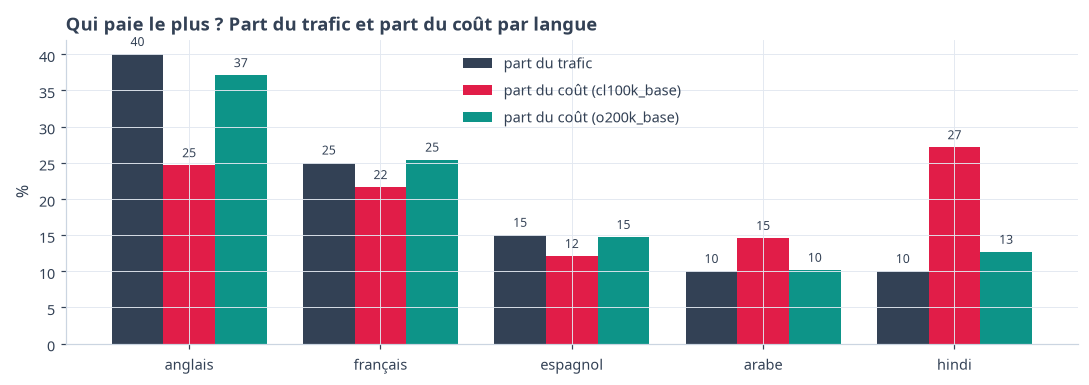

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
langs = [m.LANG_NAMES[l] for l in traffic]
x = np.arange(len(langs))
ax.bar(x - 0.27, [traffic[l] * 100 for l in traffic], 0.27, color=SLATE, label="part du trafic")
for k, (name, c) in enumerate(zip(encs, [ROSE, TEAL])):
    ax.bar(x + k * 0.27, res.loc[name, [f"part {n}" for n in langs]].values * 100, 0.27, color=c,
           label=f"part du coût ({name})")
annotate_bars(ax, "{:.0f}", fontsize=8)
ax.set_xticks(x, langs); ax.set_ylabel("%"); ax.legend()
ax.set_title("Qui paie le plus ? Part du trafic et part du coût par langue")
plt.tight_layout(); plt.show()

Avec `cl100k_base`, les 10 % d'utilisateurs hindiphones pèsent nettement plus que 10 % de
la facture (chaque requête en hindi coûte plusieurs fois une requête en anglais) ; avec
`o200k_base`, dont le vocabulaire couvre mieux le devanagari, l'écart se réduit
fortement. Le choix du modèle (et donc du tokenizer) a ainsi un effet direct sur le coût
par marché, et aussi sur la latence et le contexte utile. Notre corpus est minuscule
(6 phrases) : en pratique, on mesure ces ratios sur un échantillon représentatif du
trafic réel.

> **À retenir.** Le surcoût linguistique moyen vaut $\sum_\ell s_\ell r_\ell$ : il se
> mesure en quelques lignes, et peut justifier à lui seul de changer de modèle pour un
> marché non anglophone.

## Exercice 2.2 : Propriétés de l'attention causale

**Énoncé.** On considère une couche d'attention à une tête, $\text{out} =
\operatorname{softmax}(QK^\top/\sqrt d + M)V$ avec $M_{ij} = -\infty$ si $j > i$, 0 sinon.

1. Montrer que la sortie en position $i$ ne dépend pas des tokens $j > i$, et le vérifier
   numériquement en perturbant les derniers tokens.
2. **Sans** masque ni encodage de position, montrer que permuter les tokens d'entrée
   permute les sorties de la même façon (équivariance). Pourquoi est-ce un problème pour
   un modèle de langue ?
3. Si l'on matérialisait la matrice des scores (sans optimisation), quelle mémoire
   faudrait-il pour Llama 2-7B (32 couches, 32 têtes) en bf16, pour un contexte de 4 096,
   32 768 et 131 072 tokens ?

**Rappels.** Section *Attention mechanism* : $Q = xW_Q$, $K = xW_K$, $V = xW_V$ ; le
masque causal empêche un token de voir le futur (cours 1, section 6). Chaque tête calcule
une matrice de scores $T \times T$.

**Solution.**

1. La ligne $i$ des poids vaut $A_{ij} = e^{s_{ij} + M_{ij}} / \sum_k e^{s_{ik} + M_{ik}}$.
   Pour $j > i$, $e^{-\infty} = 0$ : ces termes disparaissent du numérateur **et** du
   dénominateur. La sortie $\sum_j A_{ij} v_j$ ne fait donc intervenir que $q_i$, et $k_j,
   v_j$ pour $j \le i$, qui ne dépendent que de $x_j$ pour $j \le i$. $\blacksquare$
2. Soit $P$ une matrice de permutation. Sans masque : $Q' = PQ$, $K' = PK$, $V' = PV$, donc
   $Q'K'^\top = P\,QK^\top P^\top$. La softmax ligne par ligne commute avec cette
   double permutation, d'où $\text{out}' = P\,A\,P^\top P V = P\,\text{out}$. $\blacksquare$
   L'attention seule voit donc un **sac de tokens** : « le chien mord l'homme » et
   « l'homme mord le chien » produiraient les mêmes représentations (permutées). D'où les
   encodages de position (appris dans GPT-2, rotatifs avec RoPE). Remarque : le masque
   causal brise lui aussi cette symétrie, ce qui donne une information de position
   implicite.
3. Mémoire : $L \times h \times T^2 \times 2$ octets. Pour $T = 4096$ :
   $32 \times 32 \times 4096^2 \times 2 \approx 34$ Go ; pour $T = 131\,072$, $1024$ fois plus,
   soit environ 35 To. Même une seule couche à la fois (1/32) reste énorme à 128 k tokens :
   d'où les noyaux comme FlashAttention, qui ne matérialisent jamais la matrice entière
   (chapitre 9).

In [4]:
T, dd = 8, 16
x = rng.normal(size=(T, dd))
Wq, Wk, Wv, Wo = rng.normal(0, 1 / np.sqrt(dd), (4, dd, dd))
out1, _ = m.multi_head_attention(x, Wq, Wk, Wv, Wo, n_heads=2, causal=True)
x2 = x.copy(); x2[5:] = rng.normal(size=(3, dd)) * 10          # on bouleverse les 3 derniers tokens
out2, _ = m.multi_head_attention(x2, Wq, Wk, Wv, Wo, n_heads=2, causal=True)
diff_pos = np.abs(out1 - out2).max(1)
perm = rng.permutation(T)
o_nc, _ = m.multi_head_attention(x, Wq, Wk, Wv, Wo, n_heads=2, causal=False)
o_perm, _ = m.multi_head_attention(x[perm], Wq, Wk, Wv, Wo, n_heads=2, causal=False)
print("1) écart de sortie par position après perturbation des tokens 5 à 7 :", np.round(diff_pos, 6))
print(f"2) sans masque : out(x permuté) == out(x) permuté ? {np.allclose(o_perm, o_nc[perm])}")
o_c_perm, _ = m.multi_head_attention(x[perm], Wq, Wk, Wv, Wo, n_heads=2, causal=True)
print(f"   avec masque causal : même test ? {np.allclose(o_c_perm, out1[perm])}")

1) écart de sortie par position après perturbation des tokens 5 à 7 : [ 0.        0.        0.        0.        0.       19.073849 20.059821
 18.264297]
2) sans masque : out(x permuté) == out(x) permuté ? True
   avec masque causal : même test ? False


**Vérification graphique** de la question 3.

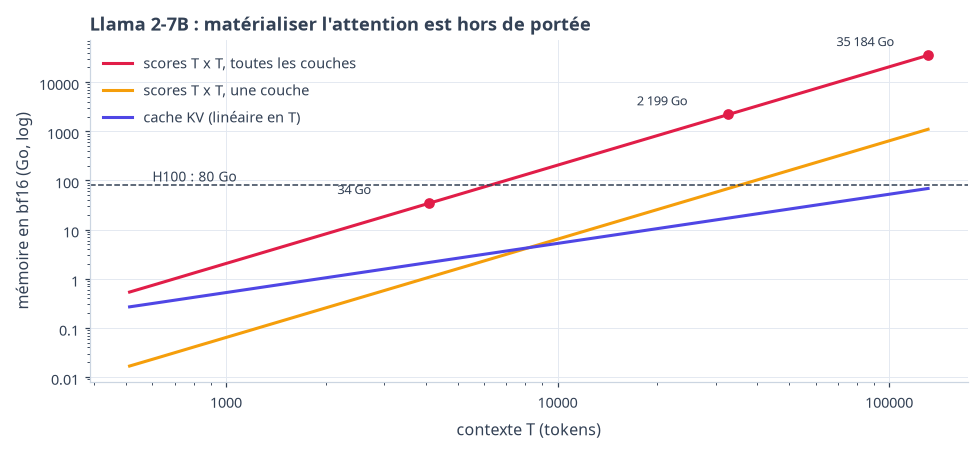

In [5]:
cfg = m.KNOWN_CONFIGS["Llama 2-7B"]
Tg = np.logspace(np.log10(512), np.log10(131072), 60)
mem_all = [m.attention_matrix_bytes(int(t), cfg.n_heads, cfg.n_layers) / 1e9 for t in Tg]
mem_one = [m.attention_matrix_bytes(int(t), cfg.n_heads, 1) / 1e9 for t in Tg]
kv = [m.kv_cache_bytes(cfg, int(t)) / 1e9 for t in Tg]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(Tg, mem_all, color=ROSE, label="scores T x T, toutes les couches")
ax.loglog(Tg, mem_one, color=AMBER, label="scores T x T, une couche")
ax.loglog(Tg, kv, color=INDIGO, label="cache KV (linéaire en T)")
ax.axhline(80, color=SLATE, ls="--", lw=1); ax.text(600, 95, "H100 : 80 Go", fontsize=9)
for t in [4096, 32768, 131072]:
    v = m.attention_matrix_bytes(t, cfg.n_heads, cfg.n_layers) / 1e9
    ax.plot(t, v, "o", color=ROSE); ax.annotate(f"{v:,.0f} Go".replace(",", " "), (t, v), xytext=(-60, 6),
                                                 textcoords="offset points", fontsize=8.5)
ax.set_xlabel("contexte T (tokens)"); ax.set_ylabel("mémoire en bf16 (Go, log)")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y")
ax.set_title("Llama 2-7B : matérialiser l'attention est hors de portée"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

> **À retenir.** Le masque causal garantit qu'un token ne voit que son passé ; sans
> positions, l'attention est aveugle à l'ordre ; et la matrice de scores croît en $T^2$, ce
> qui interdit de la matérialiser pour les longs contextes.

## Exercice 2.3 : Paramètres et mémoire à partir de la configuration

**Énoncé.** La configuration publique de Mistral-7B est : $d = 4096$, $L = 32$,
$d_{ff} = 14\,336$ (MLP SwiGLU), $V = 32\,000$, $h = 32$ têtes de requêtes, $h_{kv} = 8$
têtes clés-valeurs (GQA), plongements **non** partagés, RMSNorm sans biais.

1. Calculer à la main le nombre de paramètres, composant par composant.
2. En déduire la mémoire des poids en bf16 et en int4, puis la taille du cache KV pour
   une conversation de 32 768 tokens en bf16.
3. Combien de conversations simultanées de 8 192 tokens peut-on servir sur un GPU de
   80 Go avec les poids en bf16 ? Et sans GQA ($h_{kv} = 32$) ?
4. Vérifier avec `m.count_params_config` et `m.kv_cache_bytes`.

**Rappels.** Cours 2, sections 1 et 2 : attention $d^2 + 2d\,h_{kv}d_h + d^2$ par bloc,
MLP SwiGLU $3d\,d_{ff}$, plongements et sortie $Vd$ chacun, normalisations $2d$ par bloc
plus $d$ ; cache KV $2Lh_{kv}d_hTb$ (section *Model Size*).

**Solution.**

1. $d_h = 4096/32 = 128$, et $h_{kv} d_h = 1024$.
   - Attention par bloc : $4096^2 + 2 \times 4096 \times 1024 + 4096^2 = 16{,}78 + 8{,}39 +
     16{,}78 = 41{,}94$ M.
   - MLP par bloc : $3 \times 4096 \times 14\,336 = 176{,}16$ M.
   - Normalisations par bloc : $2 \times 4096 = 8192$.
   - Total des 32 blocs : $32 \times 218{,}11 \text{ M} = 6{,}98$ G.
   - Plongements + sortie : $2 \times 32\,000 \times 4096 = 262{,}1$ M ; norme finale : 4096.
   - **Total : environ 7,24 milliards** de paramètres.
2. Poids : $7{,}24\cdot10^9 \times 2 \approx 14{,}5$ Go en bf16, $\approx 3{,}6$ Go en int4.
   Cache KV à 32 768 tokens : $2 \times 32 \times 8 \times 128 \times 32\,768 \times 2 =
   4{,}29\cdot10^9$ octets, soit 4 Gio.
3. Mémoire libre : $80 - 14{,}5 = 65{,}5$ Go (on néglige activations et fragmentation).
   Une conversation de 8 192 tokens occupe 1 Gio $\approx 1{,}07$ Go avec GQA, d'où environ
   **61 conversations** ; sans GQA, le cache est 4 fois plus gros (4,3 Go), d'où environ
   **15 conversations**. La GQA quadruple ici la capacité de service.

In [6]:
mistral = m.TransformerConfig("Mistral-7B", 4096, 32, 14336, 32000, 32, 8, context=32768)
mistral_mha = m.TransformerConfig("Mistral-7B sans GQA", 4096, 32, 14336, 32000, 32, 32, context=32768)
N = m.count_params_config(mistral)
print("répartition :", {k: f"{v / 1e6:.1f} M" for k, v in m.param_breakdown(mistral).items() if v})
print(f"total : {N:,} paramètres".replace(",", " "))
print(f"poids bf16 : {m.weights_memory_gb(N, 2):.1f} Go ; int4 : {m.weights_memory_gb(N, 0.5):.1f} Go")
print(f"cache KV 32k tokens : {m.kv_cache_bytes(mistral, 32768) / 2**30:.2f} Gio")
free = 80e9 - N * 2
for c in [mistral, mistral_mha]:
    print(f"{c.name} : {int(free // m.kv_cache_bytes(c, 8192))} conversations de 8 192 tokens")

répartition : {'embeddings': '131.1 M', 'attention': '1342.2 M', 'mlp': '5637.1 M', 'normalisations': '0.3 M', 'tête de sortie': '131.1 M'}
total : 7 241 732 096 paramètres
poids bf16 : 14.5 Go ; int4 : 3.6 Go
cache KV 32k tokens : 4.00 Gio
Mistral-7B : 61 conversations de 8 192 tokens
Mistral-7B sans GQA : 15 conversations de 8 192 tokens


**Vérification graphique** : nombre de conversations servies en fonction de leur longueur.

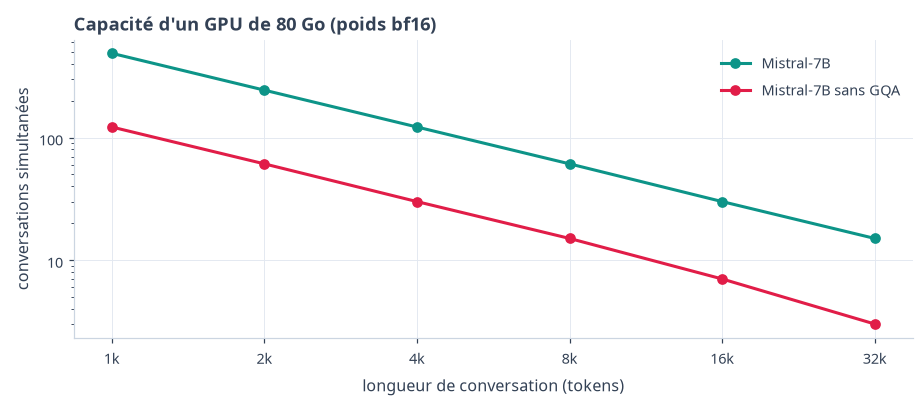

In [7]:
lens = np.array([1024, 2048, 4096, 8192, 16384, 32768])
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for c, col in [(mistral, TEAL), (mistral_mha, ROSE)]:
    ax.plot(lens, [free // m.kv_cache_bytes(c, int(t)) for t in lens], "o-", color=col, label=c.name)
ax.set_xscale("log", base=2); ax.set_xticks(lens, [f"{t // 1024}k" for t in lens])
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_xlabel("longueur de conversation (tokens)"); ax.set_ylabel("conversations simultanées")
ax.set_title("Capacité d'un GPU de 80 Go (poids bf16)"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Avec la configuration, on calcule en quelques lignes paramètres, mémoire
> des poids et cache KV, et donc la capacité de service. La GQA divise le cache par
> $h/h_{kv}$.

## Exercice 2.4 : FLOPs, durée, coût et énergie d'un pré-entraînement

**Énoncé.** Llama 3-8B (8,03 milliards de paramètres) a été entraîné sur environ
15 000 milliards de tokens.

1. Estimer le calcul d'entraînement avec la règle $6ND$.
2. Sur 4 096 GPU H100 (989 TFLOP/s en bf16 dense, crête) utilisés à 40 %, combien de
   jours faut-il ? Combien d'heures-GPU, et quel coût entre 2 et 5 \$ de l'heure ?
3. Avec une consommation d'environ 0,7 kW par GPU, quelle énergie (GPU seuls) ?
4. L'inférence coûte environ $2N$ FLOPs par token traité. Combien de tokens faut-il servir
   pour que l'inférence cumulée égale le coût d'entraînement ? Commenter.

**Rappels.** Section *Model Size* : $C \approx 6ND$ ; durée $= C / (n \cdot F \cdot u)$ avec
$F$ le débit crête et $u$ l'utilisation ; ne pas confondre FLOPs (quantité) et FLOP/s
(vitesse).

**Solution.**

1. $C = 6 \times 8{,}03\cdot10^9 \times 15\cdot10^{12} \approx 7{,}2\cdot10^{23}$ FLOPs.
2. Débit effectif par GPU : $0{,}4 \times 989\cdot10^{12} \approx 3{,}96\cdot10^{14}$ FLOP/s.
   Heures-GPU : $7{,}2\cdot10^{23} / 3{,}96\cdot10^{14} / 3600 \approx 5{,}1\cdot10^5$, soit environ
   500 000 heures-GPU ; sur 4 096 GPU, environ 124 heures, soit **5 jours**. Coût : de
   1 à 2,5 millions de dollars.
3. $5{,}1\cdot10^5 \text{ h} \times 0{,}7 \text{ kW} \approx 355$ MWh.
4. $2N D_{\text{inf}} = 6ND \Rightarrow D_{\text{inf}} = 3D = 45\,000$ milliards de tokens.
   Énorme en apparence, mais un service populaire traitant 100 milliards de tokens par jour
   l'atteindrait en 450 jours : pour un modèle très utilisé, l'inférence finit par dominer.
   C'est l'argument de Sardana et al. pour des modèles plus petits et sur-entraînés (cours
   2, section 7). Ces chiffres sont des ordres de grandeur : les durées réelles incluent
   pannes, redémarrages et expériences préalables.

In [8]:
N8, D8 = 8.03e9, 15e12
C8 = m.training_flops(N8, D8)
peak_h100 = 989e12
hours = C8 / (peak_h100 * 0.4) / 3600
print(f"C = {C8:.2e} FLOPs")
print(f"heures-GPU : {hours:,.0f} ; durée sur 4096 GPU : {m.training_days(C8, 4096, peak_h100, 0.4):.1f} jours"
      .replace(",", " "))
print(f"coût : {m.training_cost(C8, peak_h100, 2, 0.4) / 1e6:.2f} à {m.training_cost(C8, peak_h100, 5, 0.4) / 1e6:.2f} M$")
print(f"énergie GPU : {hours * 0.7 / 1000:.0f} MWh")
print(f"tokens d'inférence équivalents : {C8 / (2 * N8):.2e}")

C = 7.23e+23 FLOPs
heures-GPU : 507 457 ; durée sur 4096 GPU : 5.2 jours
coût : 1.01 à 2.54 M$
énergie GPU : 355 MWh
tokens d'inférence équivalents : 4.50e+13


**Vérification graphique** : calcul cumulé (entraînement + inférence) selon le volume
servi, pour Llama 3-8B et pour un modèle de 70 milliards de paramètres entraîné sur le
même nombre de tokens.

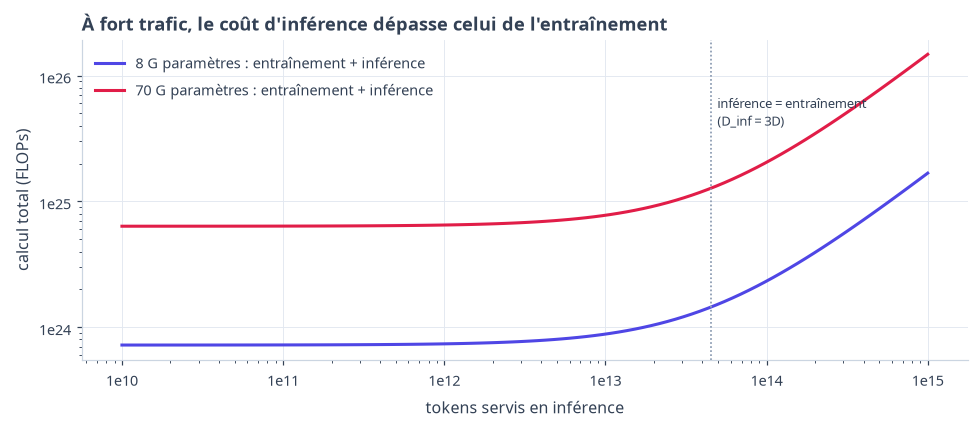

In [9]:
served = np.logspace(10, 15, 100)
fig, ax = plt.subplots(figsize=(9, 4))
for n_, col, lab in [(8.03e9, INDIGO, "8 G paramètres"), (70.6e9, ROSE, "70 G paramètres")]:
    ax.loglog(served, m.training_flops(n_, D8) + 2 * n_ * served, color=col, label=f"{lab} : entraînement + inférence")
    ax.axvline(3 * D8, color=GRAY, ls=":", lw=1)
ax.text(3 * D8 * 1.1, 4e25, "inférence = entraînement\n(D_inf = 3D)", fontsize=8.5)
ax.set_xlabel("tokens servis en inférence"); ax.set_ylabel("calcul total (FLOPs)")
m.plain_log_axis(ax, fmt=sci); m.plain_log_axis(ax, "y", sci)
ax.set_title("À fort trafic, le coût d'inférence dépasse celui de l'entraînement"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** $6ND$ donne le budget, le débit crête et l'utilisation donnent la durée,
> le prix horaire donne le coût. Pour un modèle très utilisé, l'inférence ($2N$ par token)
> dépasse vite l'entraînement.

## Exercice 2.5 : Dimensionner un modèle avec la loi de Chinchilla

**Énoncé.** Une équipe dispose d'un budget de 500 000 \$ pour pré-entraîner un modèle :
H100 à 2,50 \$ de l'heure, 989 TFLOP/s crête en bf16, utilisation de 40 %.

1. Quel budget de calcul $C$ (FLOPs) cela représente-t-il ?
2. Avec la règle des 20 tokens par paramètre, quelles valeurs de $N^\star$ et $D^\star$ ?
   Et avec l'ajustement paramétrique de Hoffmann et al. ?
3. L'équipe préfère un modèle de 1 milliard de paramètres (moins cher à servir), avec le
   même budget. Combien de tokens, et quelle perte prédite par rapport à l'optimum ?
4. Le corpus de qualité disponible dans la langue visée ne fait que 100 milliards de
   tokens. Que faire ?

**Rappels.** Section *Scaling law* : $L(N, D) = E + A/N^\alpha + B/D^\beta$ (cours 2,
section 7) ; compute-optimal à environ $D \approx 20N$ ; $C = 6ND$.

**Solution.**

1. Heures-GPU : $500\,000 / 2{,}5 = 200\,000$ h. Calcul : $2\cdot10^5 \times 3600 \times 0{,}4
   \times 989\cdot10^{12} \approx 2{,}85\cdot10^{23}$ FLOPs (l'ordre de grandeur de GPT-3).
2. Règle des 20 : $C = 6N \cdot 20N = 120N^2$, donc $N^\star = \sqrt{C/120} \approx 49$
   milliards et $D^\star \approx 970$ milliards de tokens. L'ajustement paramétrique donne
   un modèle environ deux fois plus petit (23 milliards) entraîné deux fois plus longtemps
   (2 000 milliards de tokens), pour une perte prédite quasi identique.
3. $D = C / (6 \times 10^9) \approx 4{,}7\cdot10^{13}$ : 47 000 milliards de tokens, un volume
   irréaliste aujourd'hui. La perte prédite monte d'environ 0,14 nat (2,10 contre 1,96) :
   un écart sensible, à mettre en regard d'un coût d'inférence divisé par 20 à 50.
4. Les tokens manquent : on peut répéter les données sur plusieurs époques (avec des
   rendements décroissants au-delà de quelques passes), compléter avec des données d'autres
   langues proches ou du code, générer des données synthétiques (chapitre 8), ou réduire
   le budget de calcul. L'hypothèse de Chinchilla, des données bon marché et abondantes,
   ne tient plus : c'est le goulot d'étranglement des données (cours 2, section 9).

In [10]:
C_budget = 500_000 / 2.5 * 3600 * 0.4 * 989e12
N20, D20 = m.chinchilla_optimal(C_budget)
Np, Dp = m.chinchilla_optimal(C_budget, "parametric")
N1 = 1e9; D1 = C_budget / (6 * N1)
tab = pd.DataFrame({"N (milliards)": [N20 / 1e9, Np / 1e9, 1.0],
                    "D (milliards de tokens)": [D20 / 1e9, Dp / 1e9, D1 / 1e9],
                    "tokens / paramètre": [D20 / N20, Dp / Np, D1 / N1],
                    "perte prédite": [float(m.chinchilla_loss(N20, D20)), float(m.chinchilla_loss(Np, Dp)),
                                      float(m.chinchilla_loss(N1, D1))]},
                   index=["règle des 20", "paramétrique", "choix 1 G"])
print(f"C = {C_budget:.2e} FLOPs")
tab.round(3)

C = 2.85e+23 FLOPs


,N (milliards),D (milliards de tokens),tokens / paramètre,perte prédite
règle des 20,48.72,974.39,20.00,1.97
paramétrique,23.42,2026.92,86.54,1.96
choix 1 G,1.00,47472.00,47472.00,2.10


**Vérification graphique** : la courbe iso-FLOP du budget et les trois choix.

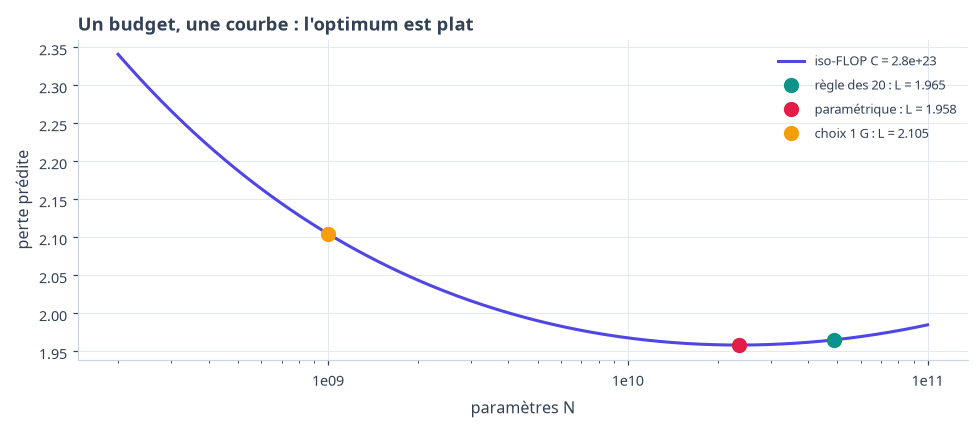

In [11]:
Ng = np.logspace(8.3, 11, 300)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(Ng, m.chinchilla_loss(Ng, C_budget / (6 * Ng)), color=INDIGO, label=f"iso-FLOP C = {C_budget:.1e}")
for (lab, row), c in zip(tab.iterrows(), [TEAL, ROSE, AMBER]):
    ax.plot(row["N (milliards)"] * 1e9, row["perte prédite"], "o", ms=9, color=c, label=f"{lab} : L = {row['perte prédite']:.3f}")
ax.set_xlabel("paramètres N"); ax.set_ylabel("perte prédite"); m.plain_log_axis(ax, fmt=sci)
ax.set_title("Un budget, une courbe : l'optimum est plat"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Autour de l'optimum, la courbe iso-FLOP est **plate** : s'écarter d'un facteur 2 à 5 en
taille coûte peu en perte. C'est ce qui rend raisonnable le choix d'un modèle plus petit
et sur-entraîné quand l'inférence compte.

> **À retenir.** Budget en dollars → heures-GPU → FLOPs → $(N^\star, D^\star)$. L'optimum de
> Chinchilla est un point de départ ; coût d'inférence et données disponibles déplacent
> souvent le choix final.

## Exercice 2.6 : Pourquoi le decode est limité par la mémoire

**Énoncé.**

1. Lors d'un pas de decode avec un batch de $B$ séquences, un modèle dense de $N$
   paramètres stockés sur $b$ octets lit tous ses poids une fois et effectue environ
   $2NB$ FLOPs. Calculer l'**intensité arithmétique** (FLOPs par octet lu), en négligeant
   le cache KV.
2. Un H100 offre 989 TFLOP/s et 3,35 To/s de bande passante mémoire. À partir de quel
   batch le decode devient-il limité par le calcul plutôt que par la mémoire ?
3. Borne supérieure de vitesse à $B = 1$ : combien de tokens par seconde au plus pour
   Llama 2-7B en bf16 sur un H100 ?
4. Mini-lab : mesurer le débit de decode de Qwen2.5-0.5B pour $B = 1, 4, 16, 64$.

**Rappels.** Cours 2, section 3 : le prefill traite beaucoup de tokens par passe (gros
produits matriciels), le decode un seul par séquence. Un calcul est limité par la mémoire
quand son intensité arithmétique est inférieure au ratio débit de calcul / bande passante
de la machine (modèle *roofline*, chapitre 9).

**Solution.**

1. Octets lus : $Nb$ ; FLOPs : $2NB$. Intensité : $I = 2NB / (Nb) = 2B/b$, soit
   $I = B$ FLOP/octet en bf16 ($b = 2$).
2. Ratio machine : $989\cdot10^{12} / 3{,}35\cdot10^{12} \approx 295$ FLOP/octet. Le decode
   reste limité par la mémoire tant que $B < 295$ : à $B = 1$, le GPU utilise moins de
   1 % de sa puissance de calcul.
3. Chaque token exige de relire $6{,}74\cdot10^9 \times 2 = 13{,}5$ Go : au mieux
   $3{,}35\cdot10^{12} / 13{,}5\cdot10^9 \approx 250$ tokens/s par séquence, quelle que soit la
   puissance de calcul.
4. Si le decode est limité par la mémoire, augmenter $B$ multiplie le débit total presque
   gratuitement : la même lecture des poids sert $B$ séquences.

In [12]:
bw, peak = 3.35e12, 989e12
print(f"ratio machine H100 : {peak / bw:.0f} FLOP/octet")
print(f"Llama 2-7B bf16, B = 1 : au plus {bw / (6.74e9 * 2):.0f} tokens/s")

tok, model = llm.load(llm.SMALL)
dev = model.device
prompt_ids = tok("Il était une fois", return_tensors="pt")["input_ids"].to(dev)
batch_res = []
with torch.no_grad():
    for B in [1, 4, 16, 64]:
        ids = prompt_ids.repeat(B, 1)
        o = model(ids, use_cache=True)
        past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        steps = 32
        for _ in range(steps):
            o = model(nxt, past_key_values=past, use_cache=True)
            past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        dt = (time.perf_counter() - t0) / steps
        batch_res.append(dict(B=B, ms_par_pas=dt * 1e3, tokens_par_s=B / dt))
br = pd.DataFrame(batch_res)
br.round(1)

ratio machine H100 : 295 FLOP/octet
Llama 2-7B bf16, B = 1 : au plus 249 tokens/s


,B,ms_par_pas,tokens_par_s
0,1,10.7,93.5
1,4,11.6,345.6
2,16,10.6,1513.4
3,64,14.9,4286.4


**Vérification graphique.**

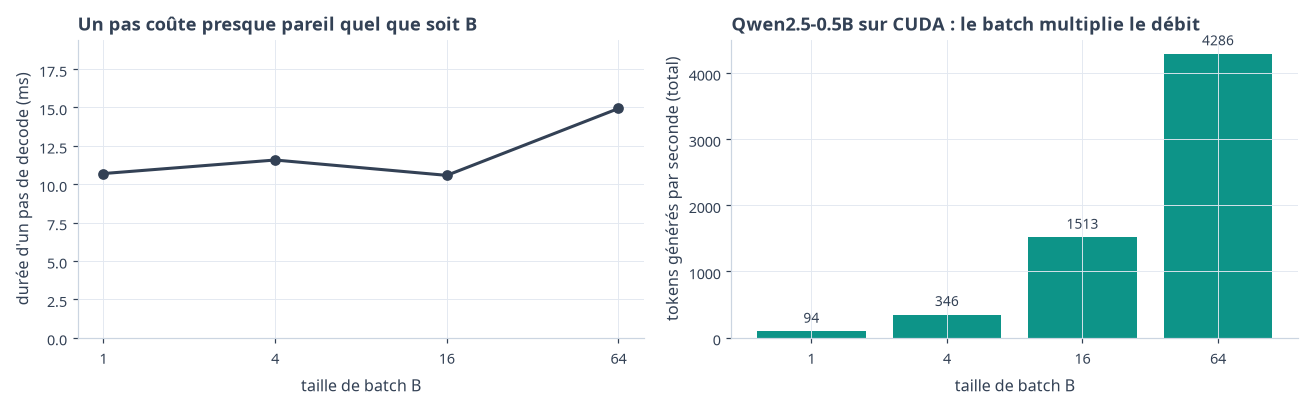

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(br.B, br.ms_par_pas, "o-", color=SLATE)
axes[0].set_xscale("log", base=2); axes[0].set_xticks(br.B, br.B)
axes[0].set_xlabel("taille de batch B"); axes[0].set_ylabel("durée d'un pas de decode (ms)")
axes[0].set_ylim(0, br.ms_par_pas.max() * 1.3); axes[0].set_title("Un pas coûte presque pareil quel que soit B")
axes[1].bar([str(b) for b in br.B], br.tokens_par_s, color=TEAL)
annotate_bars(axes[1], "{:.0f}")
axes[1].set_xlabel("taille de batch B"); axes[1].set_ylabel("tokens générés par seconde (total)")
axes[1].set_title(f"Qwen2.5-0.5B sur {dev.type.upper()} : le batch multiplie le débit")
plt.tight_layout(); plt.show()

La durée d'un pas augmente bien moins vite que $B$ : le débit total croît presque
linéairement avec la taille de batch. Pour un modèle aussi petit, une part du temps est
même due aux surcoûts fixes (lancement des noyaux GPU, Python), autre raison pour laquelle
le batch est rentable. Les mesures dépendent du matériel et de la charge du GPU.

> **À retenir.** Au decode, l'intensité arithmétique vaut environ $2B/b$ : à petit batch,
> la vitesse est bornée par la bande passante mémoire (poids relus à chaque token). Le
> batching (chapitre 9) amortit cette lecture sur de nombreuses requêtes.

In [14]:
llm.free_gpu()